# **TP0 - Introduction**

Corrigé proposé par *Groupe 4*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
import datetime
from pathlib import Path
import matplotlib.dates as mdates

## **Chargement et prétraitement des données**

In [2]:
## Data preprocessing
path = Path("../data")

# Import Consumption data
data = pd.read_csv(path / "rte.csv", sep=";")
data = data.dropna(subset=["Consommation"])
data = data[["DateTime", "Consommation"]]
data["DateTime"] = pd.to_datetime(data["DateTime"], format="%Y-%m-%d %H:%M:%S", utc=True)

# Import Calendar data
calendar = pd.read_csv(path / "calendar.csv", sep=";", decimal=",")
calendar["DateTime"] = pd.to_datetime(calendar["DateTime"], format="%Y-%m-%d %H:%M:%S", utc=True)

# Import meteo data
meteo = pd.read_csv(path / "meteo.csv", sep=";", decimal=",")


In [3]:
# Filter for mainland France stations
stationsMetropole = [
    "ABBEVILLE", "LILLE-LESQUIN", "PTE DE LA HAGUE", "CAEN-CARPIQUET",
    "ROUEN-BOOS", "BREST-GUIPAVAS", "PLOUMANAC'H", "RENNES-ST JACQUES",
    "ALENCON", "ORLY", "TROYES-BARBEREY", "NANCY-OCHEY", "STRASBOURG-ENTZHEIM",
    "BELLE ILE-LE TALUT", "NANTES-BOUGUENAIS", "TOURS", "BOURGES",
    "DIJON-LONGVIC", "BALE-MULHOUSE", "PTE DE CHASSIRON", "POITIERS-BIARD",
    "LIMOGES-BELLEGARDE", "CLERMONT-FD", "LE PUY-LOUDES", "LYON-ST EXUPERY",
    "BORDEAUX-MERIGNAC", "GOURDON", "MILLAU", "MONTELIMAR", "EMBRUN",
    "MONT-DE-MARSAN", "TARBES-OSSUN", "ST GIRONS", "TOULOUSE-BLAGNAC",
    "MONTPELLIER", "MARIGNANE", "CAP CEPET", "NICE", "PERPIGNAN"
]

meteo["DateTime"] = pd.to_datetime(meteo["DateTime"], format="%Y-%m-%d %H:%M:%S", utc=True)
meteo = meteo[meteo["Station"].isin(stationsMetropole)]
meteo = meteo.groupby("DateTime").agg(
    Temperature=pd.NamedAgg(column="Temperature", aggfunc="mean"),
    Nebulosity=pd.NamedAgg(column="Nebulosity", aggfunc="mean"),
    Humidity=pd.NamedAgg(column="Humidity", aggfunc="mean")).reset_index()

# Merge dataframes and select data from 2016-01-01 00:00:00 to 2023-05-31 23:30:00
start_date = pd.to_datetime("2016-01-01 00:00", format="%Y-%m-%d %H:%M", utc=True)
end_date = pd.to_datetime("2023-06-01 00:00", format="%Y-%m-%d %H:%M", utc=True)

data = data.merge(meteo, on="DateTime", how="outer")
data = data.merge(calendar, on="DateTime")
data = data[(data["DateTime"] >= start_date) & (data["DateTime"] < end_date)]


In [4]:
# Interpolate linearly weather variables
for col in ['Temperature', 'Nebulosity', 'Humidity']:
    data[col] = data[col].interpolate(method='linear')

In [5]:
data = data.sort_values(by=["DateTime"])
data.to_csv(path / "data.csv", index=False)

## **Série de consommation : saisonnalité à différentes échelles**

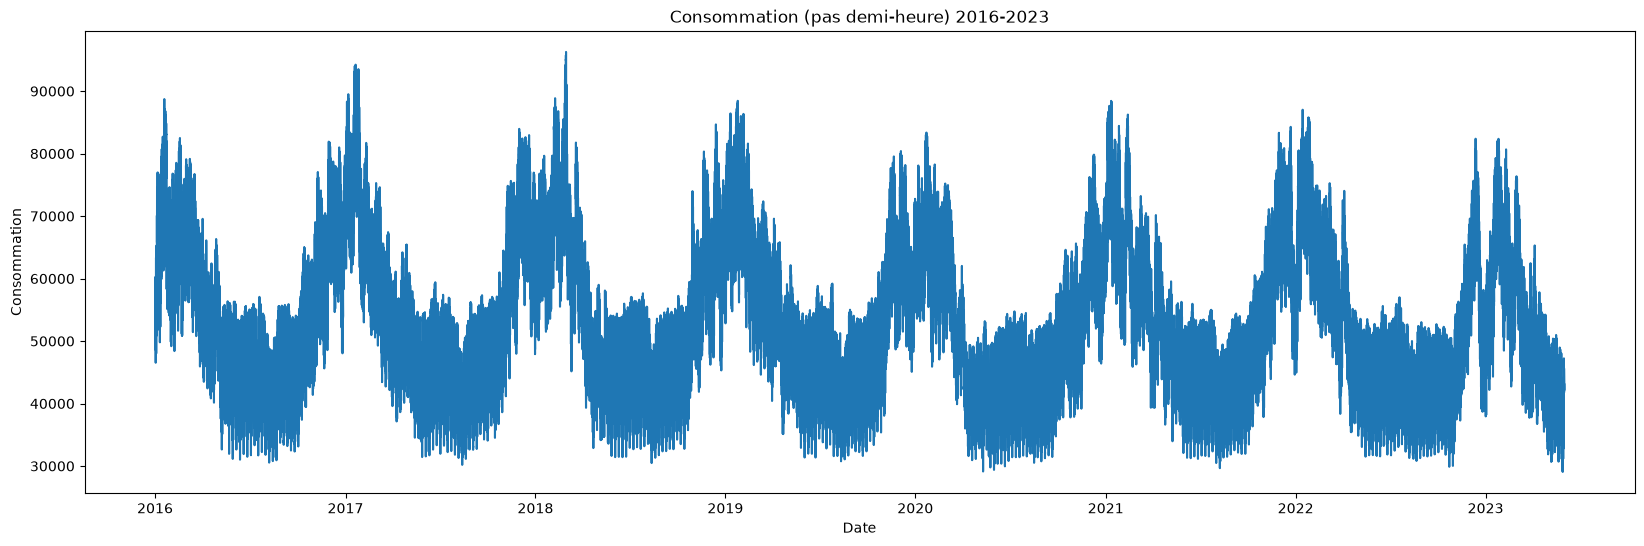

In [6]:
## Descriptive Analysis

# Plot the consumption time series
plt.figure(figsize=(20, 6))
plt.plot(data["DateTime"], data["Consommation"])
plt.title("Consommation (pas demi-heure) 2016-2023")
plt.xlabel("Date")
plt.ylabel("Consommation")
plt.show()

<Figure size 2000x600 with 0 Axes>

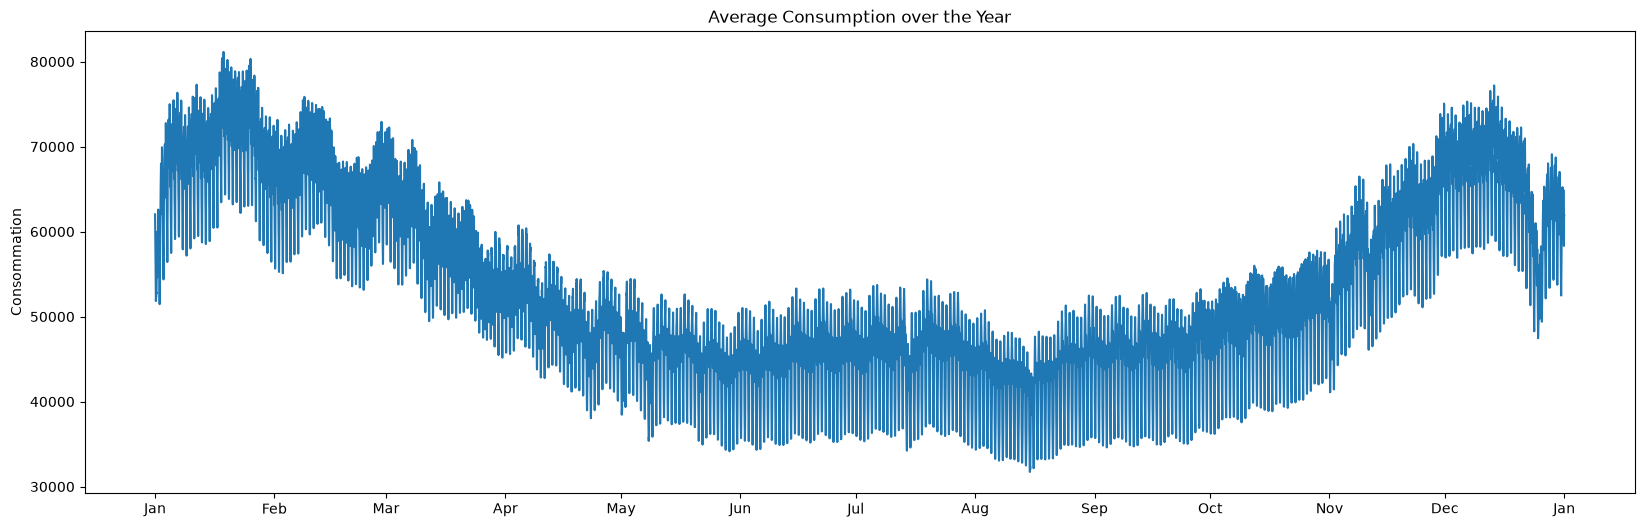

In [7]:
# Plot the annual average consumption 
data["MJour"] = data["DateTime"].dt.day
monthly_avg = data.groupby(["DemiHeure", "Mois", "MJour"]).agg(Consommation=("Consommation", "mean"), DateTime =("DateTime" ,"first")).reset_index()

plt.figure(figsize=(20, 6))
fig, ax = plt.subplots(figsize=(20, 6))
sns.lineplot(x="DateTime", y="Consommation", data=monthly_avg, ax=ax)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.xlabel("")
plt.ylabel("Consommation")
plt.title("Average Consumption over the Year")
plt.show()

Ici l'idée serait de produire un profil moyen d'une année type à pas demi-horaire, moyenné sur toutes les années.

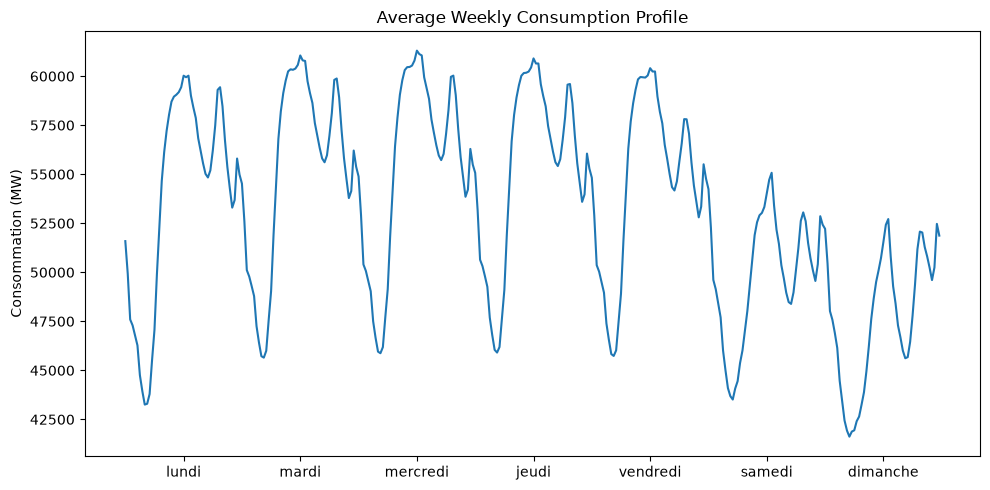

In [8]:
# Plot the Weekly average consumption

ordre_jour = ['lundi', 'mardi', 'mercredi', 'jeudi', 'vendredi', 'samedi', 'dimanche']

weekly_avg = data.groupby(["Jour", "DemiHeure"]).agg(Consommation=("Consommation", "mean")).reset_index()
weekly_avg['Jour'] = pd.Categorical(weekly_avg['Jour'], categories=ordre_jour, ordered=True)
weekly_avg = weekly_avg.sort_values(['Jour', 'DemiHeure']).reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(weekly_avg.index, weekly_avg['Consommation'])

ticks = [i * 48 + 24 for i in range(7)]

plt.xticks(ticks, ordre_jour)
plt.ylabel('Consommation (MW)')
plt.title('Average Weekly Consumption Profile')
plt.tight_layout()
plt.show()

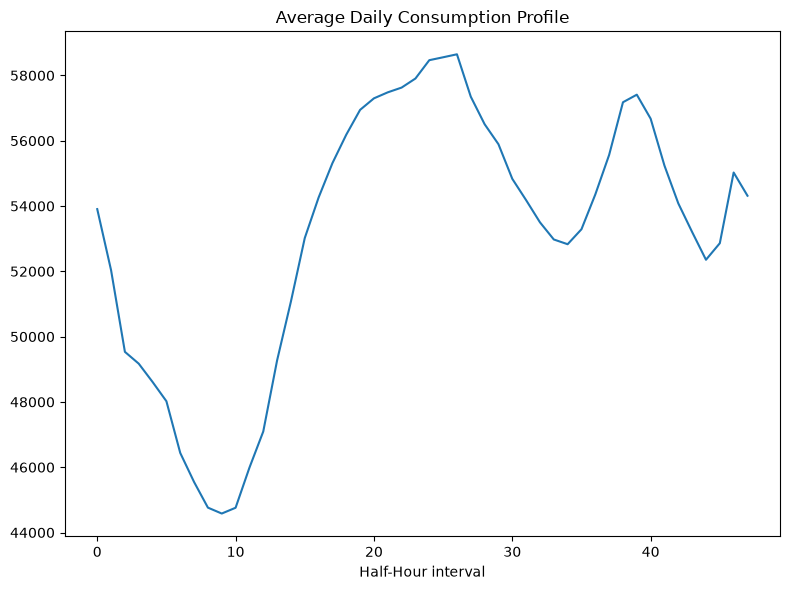

In [9]:
# Plot the Daily average consumption
daily_avg = data.groupby("DemiHeure").agg(Consommation=("Consommation", "mean")).reset_index()

plt.figure(figsize=(8, 6))
plt.plot(daily_avg['DemiHeure'], daily_avg['Consommation'])
plt.xlabel('Half-Hour interval')
plt.ylabel("")
plt.title('Average Daily Consumption Profile')
plt.tight_layout()
plt.show()

## **Périodes particulières**

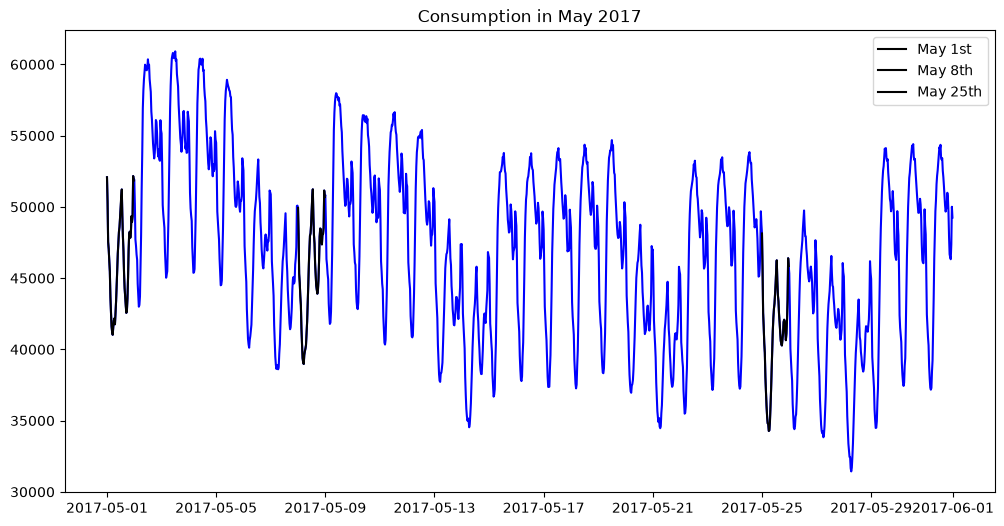

In [10]:
## Observe the consumption over particular periods (may 2017 and dec 2017- fev 2018 
## and underline bank holidays, holidays, e.g.)
data['Annee'] = data['DateTime'].dt.year

# Plot the consumption for May 2017
may_2017_data = data[(data['Annee'] == 2017) & (data['Mois'] == 'mai')]
may_2017_data_1 = may_2017_data[may_2017_data['MJour'] == 1]
may_2017_data_8 = may_2017_data[may_2017_data['MJour'] == 8]
may_2017_data_25 = may_2017_data[may_2017_data['MJour'] == 25]

plt.figure(figsize=(12, 6))
plt.plot(may_2017_data['DateTime'], may_2017_data['Consommation'], color='blue')
plt.plot(may_2017_data_1['DateTime'], may_2017_data_1['Consommation'], color='black', label='May 1st')
plt.plot(may_2017_data_8['DateTime'], may_2017_data_8['Consommation'], color='black', label='May 8th')
plt.plot(may_2017_data_25['DateTime'], may_2017_data_25['Consommation'], color='black', label='May 25th')
plt.xlabel('')
plt.ylabel('')
plt.title('Consumption in May 2017')
plt.legend()
plt.show()


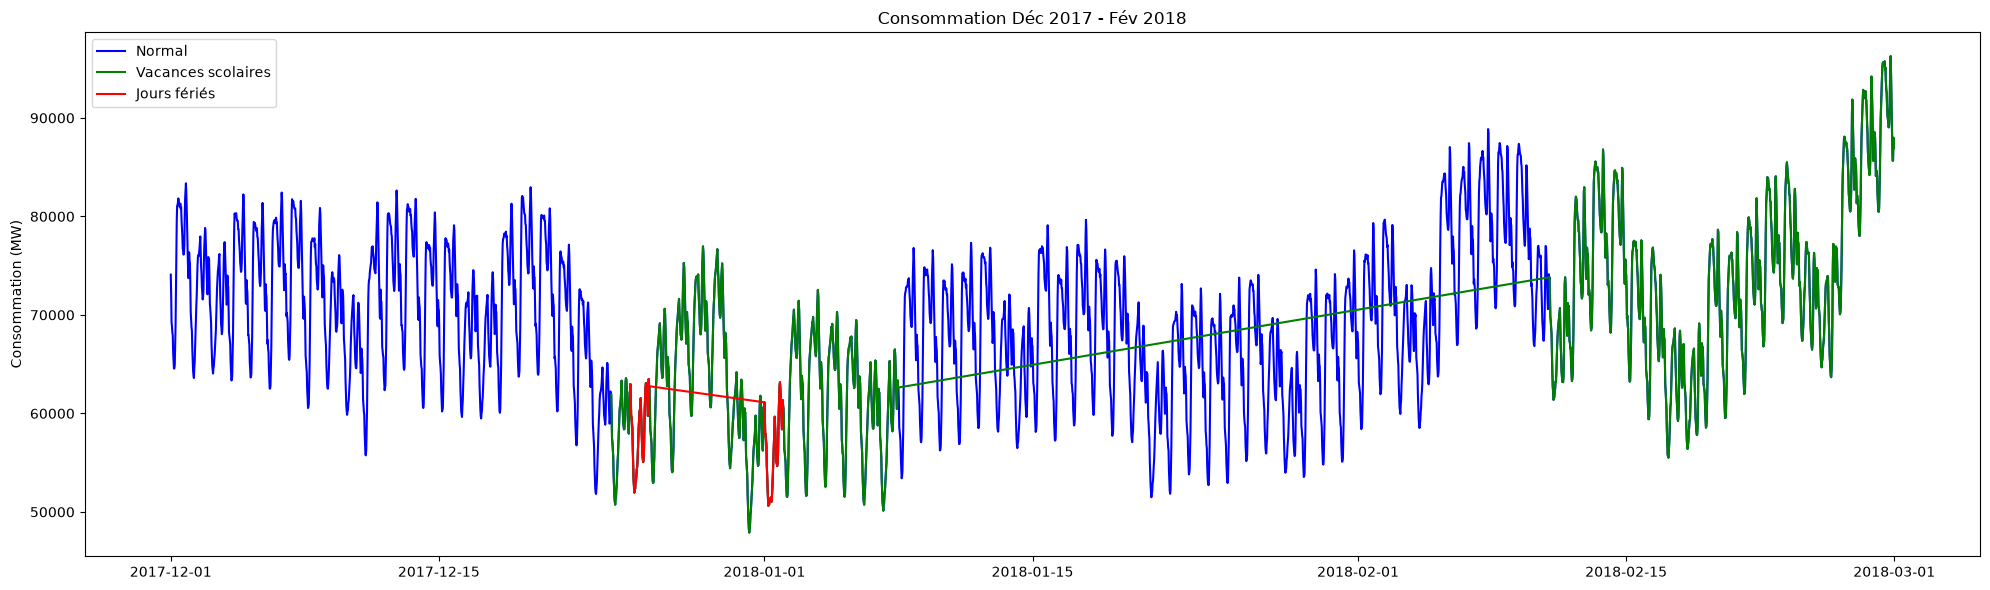

In [11]:
# dec 2017 - fev 2018
# Plot the consumption with different colors for 'Vacances'


interval_start = pd.to_datetime("2017-12-01", utc=True)
interval_end = pd.to_datetime("2018-03-01", utc=True)
interval_data = data[(data['DateTime'] >= interval_start) & (data['DateTime'] < interval_end)]

ferie_data = interval_data[interval_data['JourFerie'] == True]
vacances_data = interval_data[(interval_data['VacancesZoneA'] == True) | (interval_data['VacancesZoneB'] == True) | (interval_data['VacancesZoneC'] == True)]

plt.figure(figsize=(20, 6))
plt.plot(interval_data['DateTime'], interval_data['Consommation'], color='blue', label='Normal')
plt.plot(vacances_data['DateTime'], vacances_data['Consommation'], color='green', label='Vacances scolaires')
plt.plot(ferie_data['DateTime'], ferie_data['Consommation'], color='red', label='Jours fériés')

plt.xlabel('')
plt.ylabel('Consommation (MW)')
plt.title('Consommation Déc 2017 - Fév 2018')
plt.legend()
plt.tight_layout()
plt.show()

et pour que le graphique soit plus joli :

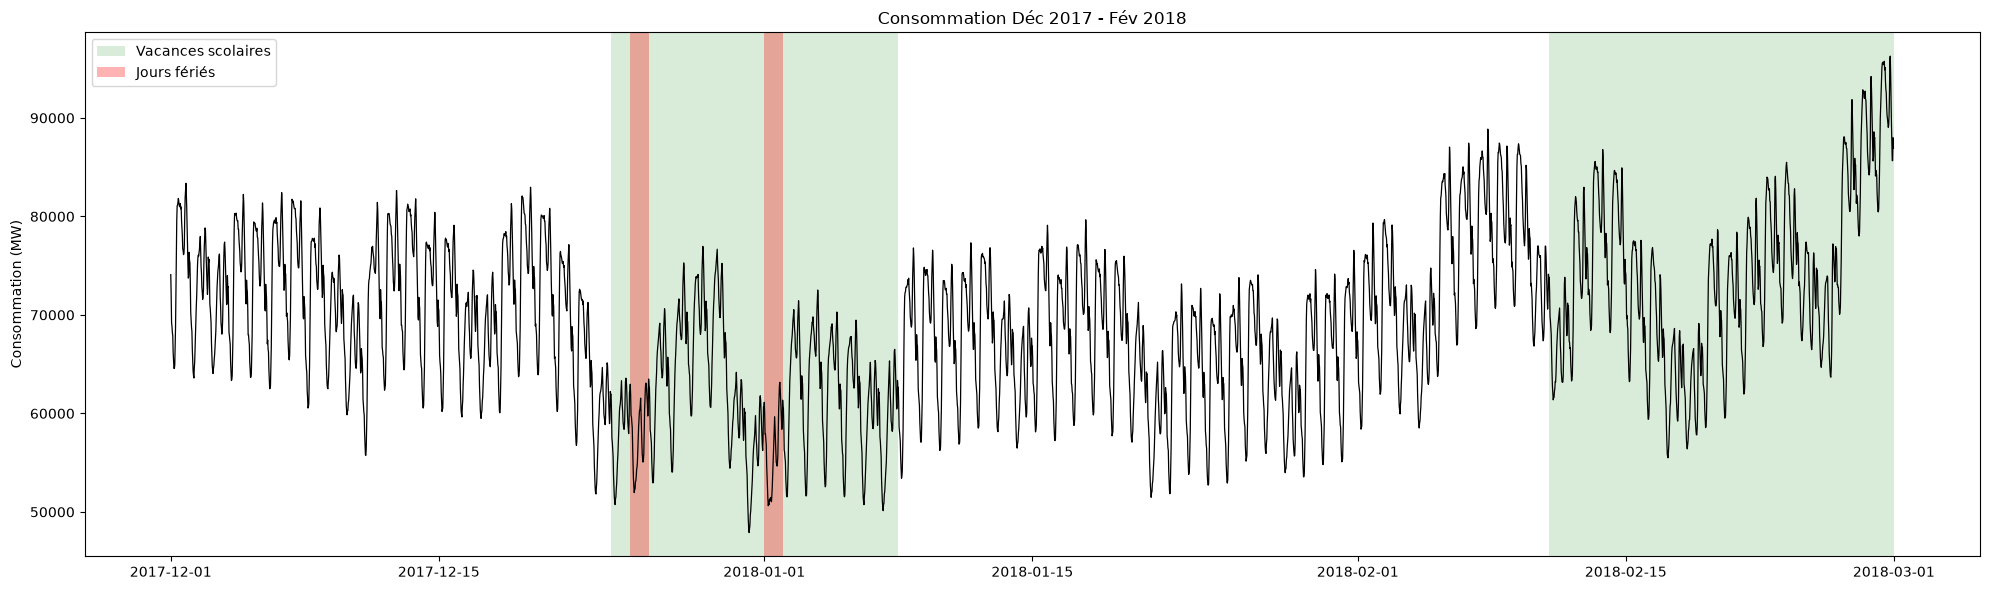

In [12]:
plt.figure(figsize=(20, 6))
plt.plot(interval_data['DateTime'], interval_data['Consommation'], 
         color='black', linewidth=0.9)

vac_dates = vacances_data['DateTime'].dt.date.unique()
fer_dates = ferie_data['DateTime'].dt.date.unique()

for d in vac_dates:
    d0 = pd.Timestamp(d, tz='UTC')
    plt.axvspan(d0, d0 + pd.Timedelta(days=1), alpha=0.15, color='green', linewidth=0)

for d in fer_dates:
    d0 = pd.Timestamp(d, tz='UTC')
    plt.axvspan(d0, d0 + pd.Timedelta(days=1), alpha=0.3, color='red', linewidth=0)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='green', alpha=0.15, label='Vacances scolaires'),
                   Patch(facecolor='red', alpha=0.3, label='Jours fériés')]
plt.legend(handles=legend_elements)

plt.xlabel('')
plt.ylabel('Consommation (MW)')
plt.title('Consommation Déc 2017 - Fév 2018')
plt.tight_layout()
plt.show()

## **Profil journalier par type de jour**

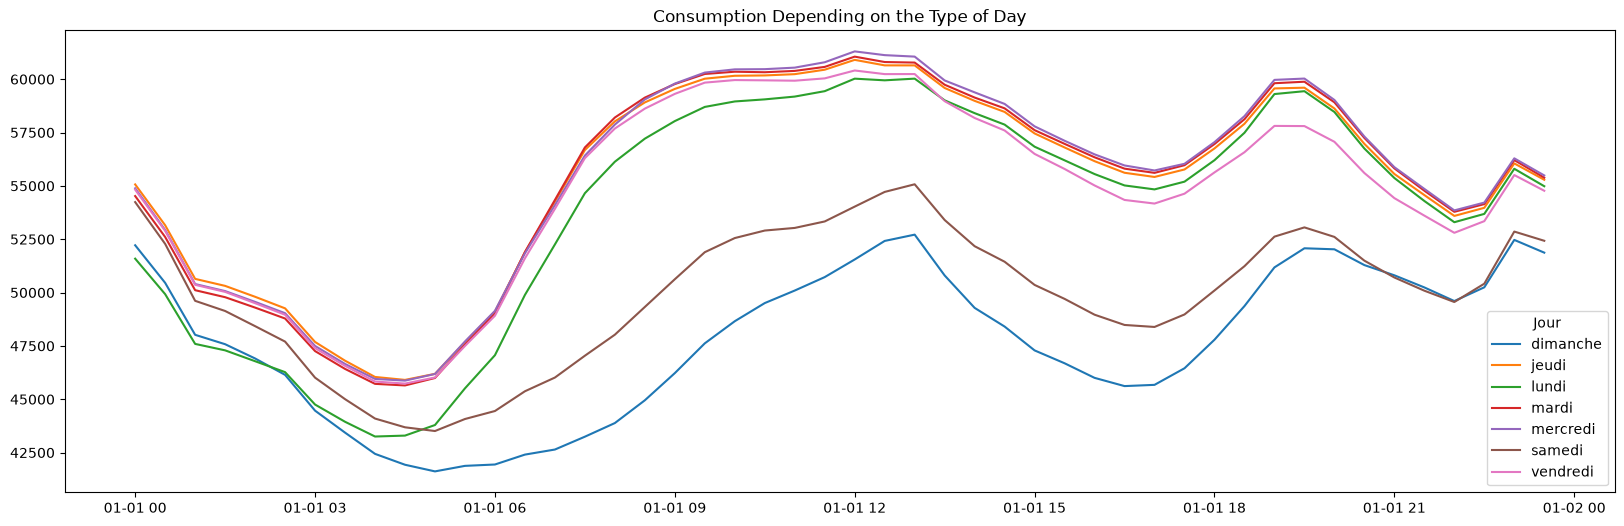

In [13]:
# Observe the consumption depending on the type of day
viz = data.groupby(["DemiHeure", "Jour"]).agg(Consommation=("Consommation", "mean"), DateTime =("DateTime" ,"first")).reset_index()
viz['DateTime'] = viz['DateTime'].apply(lambda x: x.replace(day=1))


plt.figure(figsize=(20, 6))
sns.lineplot(x='DateTime', y='Consommation', hue='Jour', data=viz)
plt.xlabel('')
plt.ylabel('')
plt.title('Consumption Depending on the Type of Day')
plt.show()

## **Impact du confinement COVID en 2020**

On va regarder les 2 confinements majeurs ayant eu lieu en 2020 :
- du 17 mars au 11 mai
- du 30 ocrobre au 15 décembre

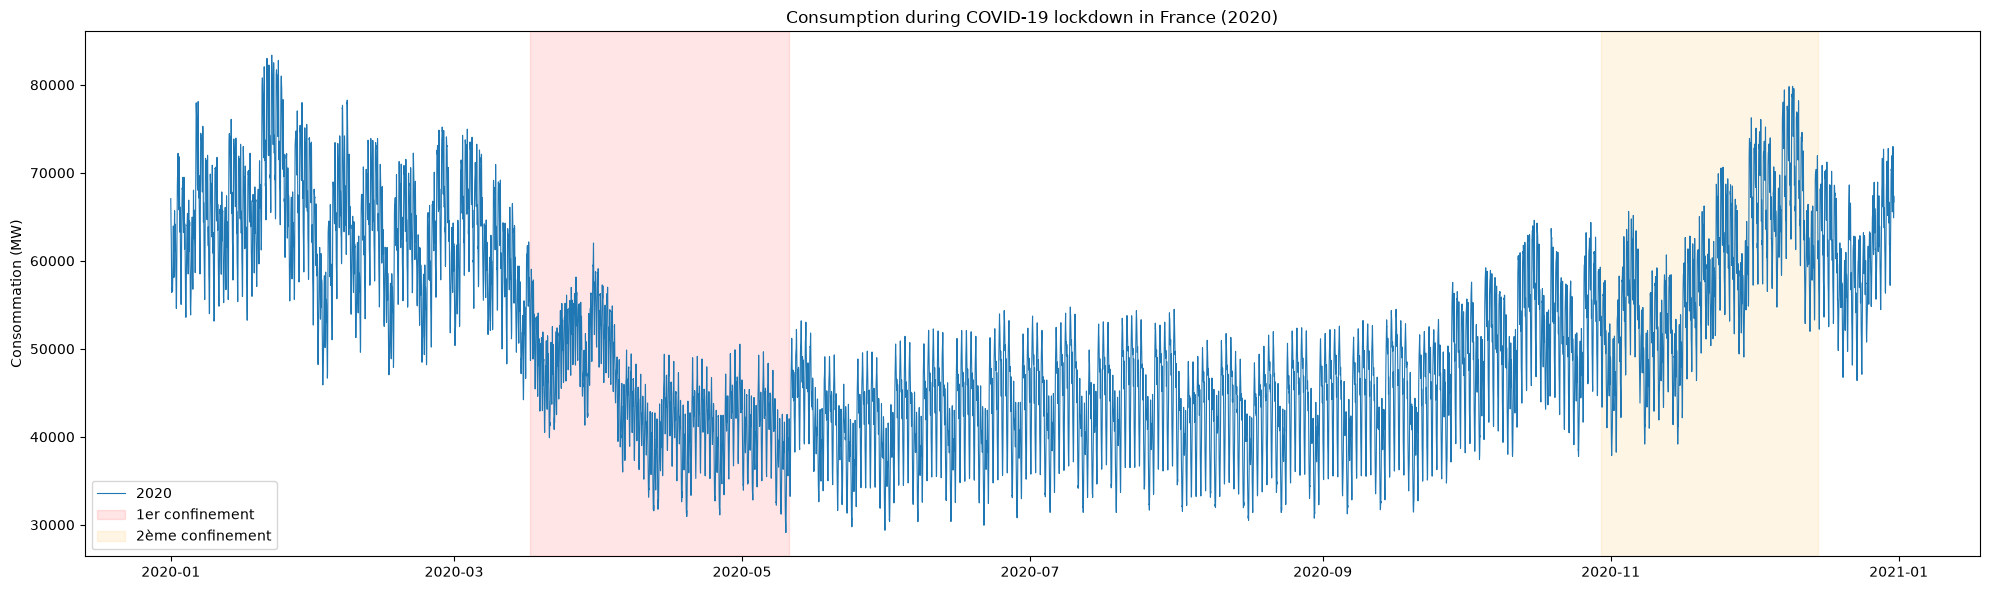

In [14]:
# Observe the consumption during the COVID lockdown

confin_start_1 = pd.to_datetime("2020-03-17", utc=True)
confin_end_1 = pd.to_datetime("2020-05-11", utc=True)
confin_start_2 = pd.to_datetime("2020-10-30", utc=True)
confin_end_2 = pd.to_datetime("2020-12-15", utc=True)

period_start_2020 = pd.to_datetime("2020-01-01", utc=True)
period_end_2020 = pd.to_datetime("2020-12-31", utc=True)

data_2020 = data[(data['DateTime'] >= period_start_2020) & (data['DateTime'] < period_end_2020)]

plt.figure(figsize=(20, 6))
plt.plot(data_2020['DateTime'], data_2020['Consommation'], linewidth=0.8, label='2020')
plt.axvspan(confin_start_1, confin_end_1, alpha=0.1, color='red', label='1er confinement')
plt.axvspan(confin_start_2, confin_end_2, alpha=0.1, color='orange', label='2ème confinement')
plt.xlabel('')  
plt.ylabel('Consommation (MW)')
plt.title('Consumption during COVID-19 lockdown in France (2020)')
plt.legend()
plt.tight_layout()
plt.show()

## **Consommation vs variables météorologiques**

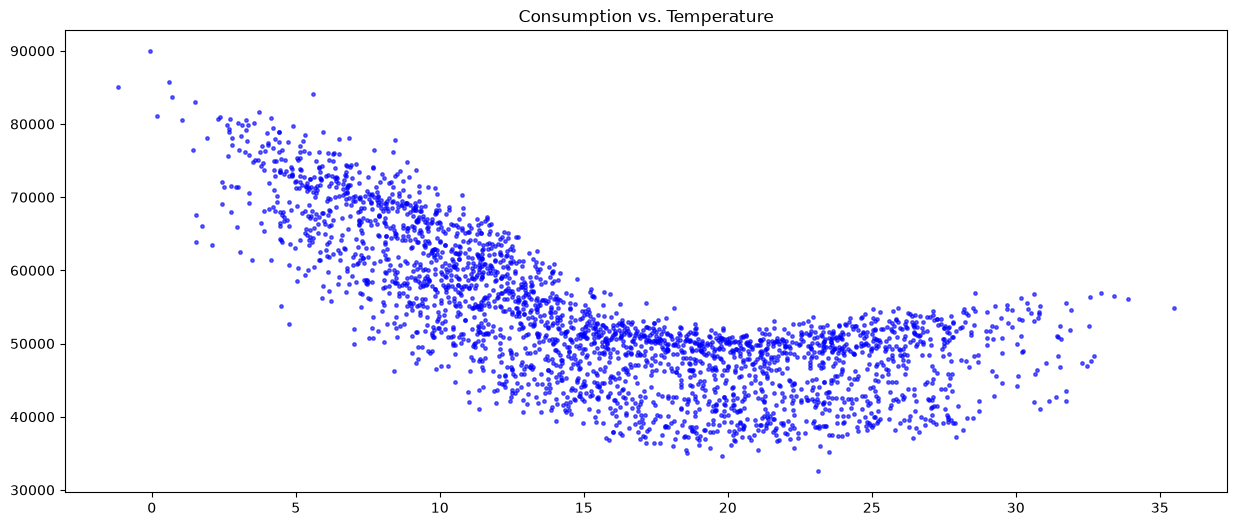

In [15]:
# Observe the consumption on some specific half-hour depending on the weather variables
temperature_data = data[data['DemiHeure'] == 32]
nebulosity_data = data[data['DemiHeure'] == 24]
humidity_data = data[data['DemiHeure'] == 24]

plt.figure(figsize=(15, 6))
plt.scatter(temperature_data['Temperature'], temperature_data['Consommation'], color='blue', s=6, alpha=0.6)
plt.xlabel('')
plt.ylabel('')
plt.title('Consumption vs. Temperature')
plt.show()

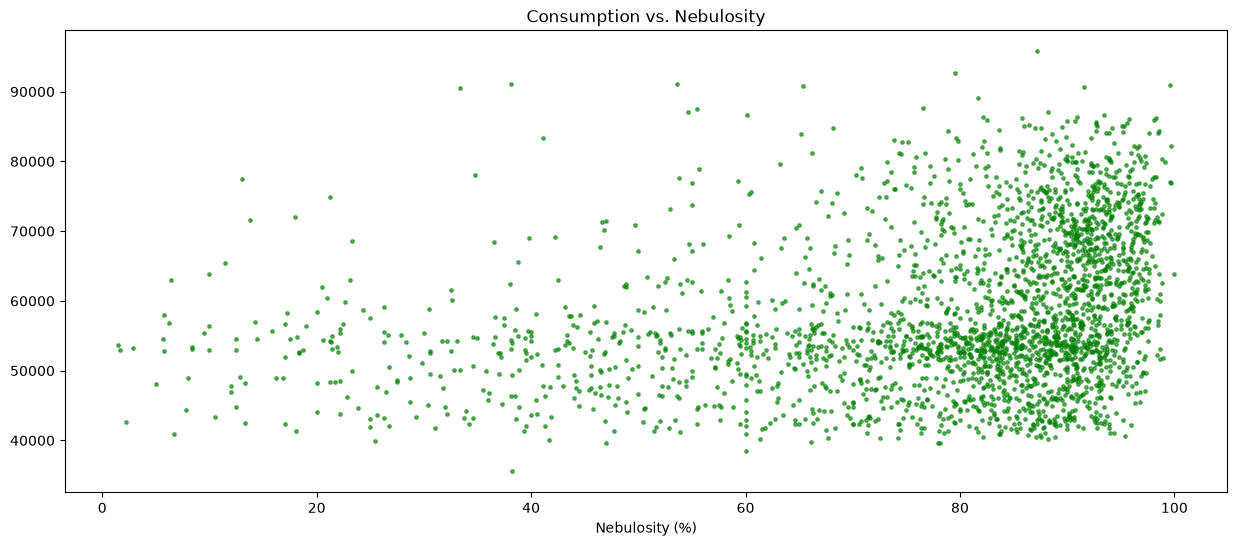

In [16]:
plt.figure(figsize=(15, 6))
plt.scatter(nebulosity_data['Nebulosity'], nebulosity_data['Consommation'], color='green', s=6, alpha=0.6)
plt.xlabel('Nebulosity (%)')
plt.ylabel('')
plt.title('Consumption vs. Nebulosity')
plt.show()

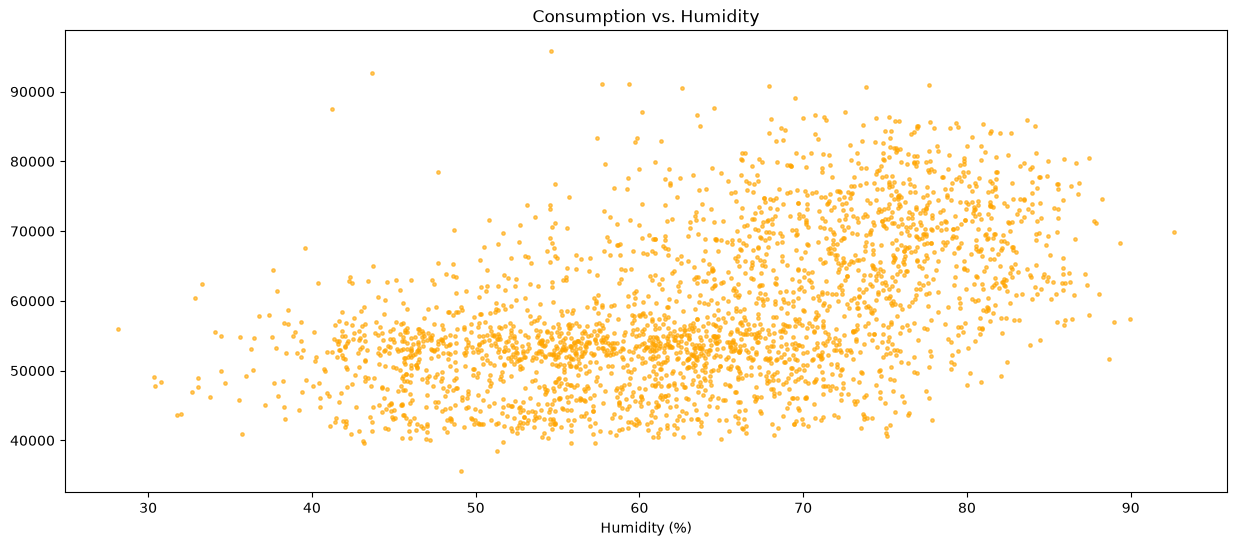

In [17]:
plt.figure(figsize=(15, 6))
plt.scatter(humidity_data['Humidity'], humidity_data['Consommation'], color='orange', s=6, alpha=0.6)
plt.xlabel('Humidity (%)')
plt.ylabel('')
plt.title('Consumption vs. Humidity')
plt.show()

## **Matrice de corrélation**

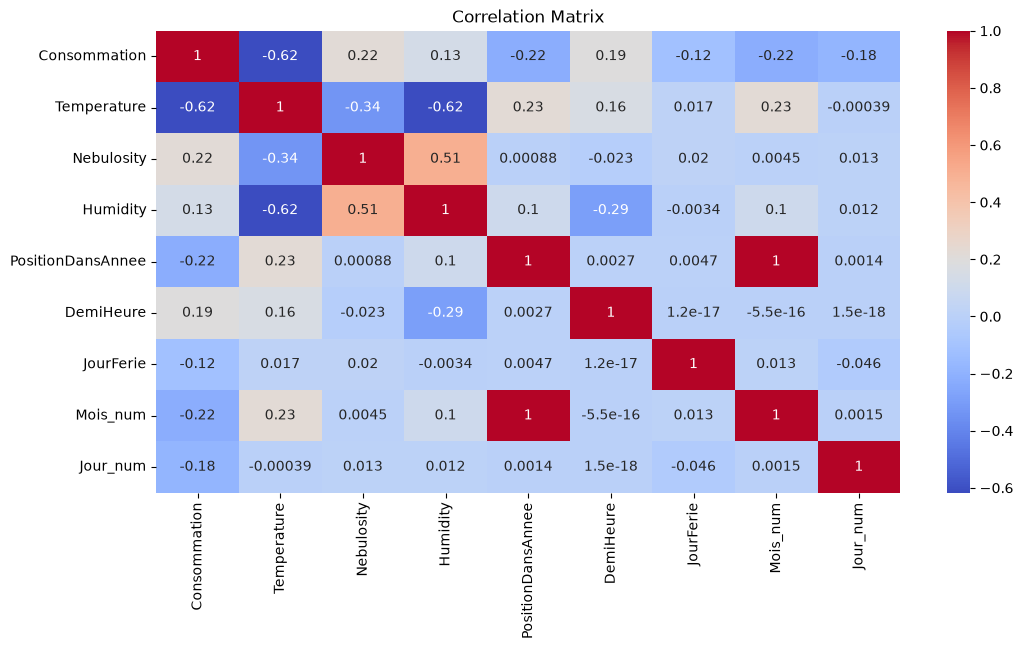

In [18]:
# Corelation matrix
data['Mois_num'] = data['DateTime'].dt.month
data['Jour_num'] = data['DateTime'].dt.weekday

cormat = data.drop(columns=['DateTime', 'Mois', 'Jour', 'MJour', 'JourFerieType', 
                            'VacancesZoneA', 'VacancesZoneB', 'VacancesZoneC', 'Annee']).corr()
melted_cormat = cormat.stack().reset_index()
melted_cormat.columns = ['Var1', 'Var2', 'value']

plt.figure(figsize=(12, 6))
sns.heatmap(cormat, annot=True, cmap='coolwarm')
plt.xlabel('')
plt.ylabel('')
plt.title('Correlation Matrix')
plt.show()